# LAB 09 — Fine-tuning Transformer for Token Classification (`ner_finetuning.ipynb`)

Notebook này triển khai đầy đủ pipeline Token Classification cho Named Entity Recognition (Mục 14, 16) và thực hiện các thí nghiệm đánh giá từ **Experiment 2 đến Experiment 5** (Mục 18–22), đồng thời xuất ma trận nhầm lẫn và dữ liệu phục vụ phân tích lỗi (`error_analysis.md`).

Tóm tắt cấu hình:
* **Dataset:** CoNLL-2003 (`train`: chọn ngẫu nhiên cố định `seed=42` gồm 6,000 câu để tối ưu thời gian chạy trên CPU; `validation`: đầy đủ 3,250 câu; `test`: **đầy đủ 3,453 câu** — giống hệt tập test của `baseline_ner.py`).
* **Backbone:** `distilbert-base-cased` ($d=768$, $C=9$ nhãn BIO).
* **Alignment Strategy:** Strategy A (gán nhãn cho subword đầu tiên, dùng `IGNORE = -100` cho các subword sau và token đặc biệt).
* **Lưu ý (Mục 16):** Không gọi tắt bằng `pipeline("ner")`; toàn bộ `tokens`, `input_ids`, `attention_mask`, `word_ids`, `labels`, `logits`, `predictions` đều được kiểm tra trực tiếp.

In [1]:
import json
import math
import random
import time
from collections import Counter, defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from datasets import load_dataset
from seqeval.metrics import (
    classification_report as seqeval_classification_report,
    f1_score as seqeval_f1,
    precision_score as seqeval_precision,
    recall_score as seqeval_recall,
)
from seqeval.metrics.sequence_labeling import get_entities
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score as sklearn_f1,
    precision_score as sklearn_precision,
    recall_score as sklearn_recall,
)
from transformers import (
    AutoModelForTokenClassification,
    AutoTokenizer,
    DataCollatorForTokenClassification,
    get_linear_schedule_with_warmup,
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(8)

LAB_DIR = Path("/Users/user/NLP/LAB09")
SCRATCH_DIR = Path("/Users/user/.gemini/antigravity/brain/d84b4b4c-6174-4ee4-afda-b95415d8f7d8/scratch")
MODEL_SAVE_DIR = SCRATCH_DIR / "ner_model"
BASELINE_JSON_PATH = SCRATCH_DIR / "baseline_metrics.json"
ERROR_DUMP_PATH = SCRATCH_DIR / "error_candidates.json"

MODEL_NAME = "distilbert-base-cased"
IGNORE_INDEX = -100
LABEL_LIST = ["O", "B-PER", "I-PER", "B-ORG", "I-ORG", "B-LOC", "I-LOC", "B-MISC", "I-MISC"]
ID2LABEL = {i: lbl for i, lbl in enumerate(LABEL_LIST)}
LABEL2ID = {lbl: i for i, lbl in enumerate(LABEL_LIST)}

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {DEVICE} | torch threads: {torch.get_num_threads()}")

Device: cpu | torch threads: 8


In [2]:
# Tải CoNLL-2003 và tokenizer
try:
    raw_datasets = load_dataset("lhoestq/conll2003")
except Exception:
    raw_datasets = load_dataset("eriktks/conll2003", trust_remote_code=True)

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

# Lấy 6,000 câu train (seed=42) để chạy hợp lý trên CPU; giữ nguyên validation (3,250) và test (3,453)
TRAIN_SUBSET_SIZE = 6000
train_raw = raw_datasets["train"].shuffle(seed=SEED).select(range(TRAIN_SUBSET_SIZE))
val_raw = raw_datasets["validation"]
test_raw = raw_datasets["test"]

print(f"Train subset: {len(train_raw)} | Validation: {len(val_raw)} | Test: {len(test_raw)}")

def tokenize_and_align(examples, max_length=256):
    tokenized = tokenizer(
        examples["tokens"],
        is_split_into_words=True,
        truncation=True,
        max_length=max_length,
    )
    aligned_labels = []
    word_id_lists = []
    for i, label_seq in enumerate(examples["ner_tags"]):
        word_ids = tokenized.word_ids(batch_index=i)
        word_id_lists.append([-1 if w is None else w for w in word_ids])
        prev_wid = None
        labels_out = []
        for w in word_ids:
            if w is None:
                labels_out.append(IGNORE_INDEX)
            elif w != prev_wid:
                labels_out.append(label_seq[w])
            else:
                labels_out.append(IGNORE_INDEX)
            prev_wid = w
        aligned_labels.append(labels_out)
    tokenized["labels"] = aligned_labels
    tokenized["word_ids_enc"] = word_id_lists
    return tokenized

train_tok = train_raw.map(tokenize_and_align, batched=True, remove_columns=train_raw.column_names)
val_tok = val_raw.map(tokenize_and_align, batched=True, remove_columns=val_raw.column_names)
test_tok = test_raw.map(tokenize_and_align, batched=True, remove_columns=test_raw.column_names)

# Kiểm tra không có câu nào trong test bị cắt cụt từ do max_length=256
truncated_test = sum(
    len(set(w for w in wids if w >= 0)) < len(orig_toks)
    for wids, orig_toks in zip(test_tok["word_ids_enc"], test_raw["tokens"])
)
print(f"Số câu test bị cắt cụt từ: {truncated_test}")

Train subset: 6000 | Validation: 3250 | Test: 3453


Map:   0%|          | 0/3453 [00:00<?, ? examples/s]

Số câu test bị cắt cụt từ: 0


## 1. Xây dựng mô hình & Fine-tuning (Mục 14 & 16)

Kiến trúc:
$$H \in \mathbb{R}^{B \times T \times 768} \xrightarrow{\text{Linear}(768, 9)} Z = HW + b \in \mathbb{R}^{B \times T \times 9}$$
Mỗi token nhận một vector logits $z_i \in \mathbb{R}^9$. Hàm loss bỏ qua các vị trí có nhãn `-100` (`IGNORE`).
Để tăng tốc độ trên CPU mà không làm lệch phân bố học, ta gom các câu có độ dài gần nhau thành từng batch (`length-grouped batching`) rồi **xáo trộn thứ tự các batch** ở mỗi epoch.

In [3]:
collator = DataCollatorForTokenClassification(tokenizer=tokenizer)

def make_length_grouped_batches(hf_dataset, batch_size=32, shuffle_batches=True, seed=42):
    lengths = [len(x) for x in hf_dataset["input_ids"]]
    sorted_indices = np.argsort(lengths).tolist()
    batches = [sorted_indices[i : i + batch_size] for i in range(0, len(sorted_indices), batch_size)]
    if shuffle_batches:
        rng = random.Random(seed)
        rng.shuffle(batches)
    return batches

def collate_subset(hf_dataset, indices):
    items = [
        {
            "input_ids": hf_dataset[int(idx)]["input_ids"],
            "attention_mask": hf_dataset[int(idx)]["attention_mask"],
            "labels": hf_dataset[int(idx)]["labels"],
        }
        for idx in indices
    ]
    return collator(items)

def decode_word_level_predictions(raw_split, tok_split, model, batch_size=64):
    """Chạy forward pass với length-sorted batching, thu logits & khôi phục nhãn BIO cấp word theo Strategy A."""
    model.eval()
    n_samples = len(tok_split)
    all_word_preds = [None] * n_samples
    all_word_golds = [None] * n_samples

    # Sắp xếp theo độ dài để giảm padding khi suy luận, sau đó trả lại đúng thứ tự gốc
    sorted_indices = sorted(range(n_samples), key=lambda idx: len(tok_split[idx]["input_ids"]))

    with torch.no_grad():
        # Lấy batch mẫu cố định [0..3] để kiểm tra đầy đủ tensors/logits ở câu test #0
        sample_batch = collate_subset(tok_split, list(range(min(4, n_samples))))
        sample_out = model(
            input_ids=sample_batch["input_ids"].to(DEVICE),
            attention_mask=sample_batch["attention_mask"].to(DEVICE),
            output_hidden_states=True,
        )
        sample_logits = sample_out.logits.cpu()
        sample_preds = sample_logits.argmax(dim=-1).numpy()
        sample_inspection = {
            "hidden_shape": tuple(sample_out.hidden_states[-1].shape),
            "logits_shape": tuple(sample_logits.shape),
            "labels_shape": tuple(sample_batch["labels"].shape),
            "input_ids": sample_batch["input_ids"][0].tolist(),
            "attention_mask": sample_batch["attention_mask"][0].tolist(),
            "labels": sample_batch["labels"][0].tolist(),
            "logits_0": sample_logits[0].numpy(),
            "preds_0": sample_preds[0].tolist(),
            "word_ids_0": tok_split[0]["word_ids_enc"],
            "orig_words_0": raw_split[0]["tokens"],
            "orig_tags_0": [ID2LABEL[t] for t in raw_split[0]["ner_tags"]],
        }

        for start in range(0, n_samples, batch_size):
            indices = sorted_indices[start : min(start + batch_size, n_samples)]
            batch = collate_subset(tok_split, indices)
            logits = model(
                input_ids=batch["input_ids"].to(DEVICE),
                attention_mask=batch["attention_mask"].to(DEVICE),
            ).logits.cpu()
            preds = logits.argmax(dim=-1).numpy()

            for b_i, ds_idx in enumerate(indices):
                orig_words = raw_split[ds_idx]["tokens"]
                orig_gold = [ID2LABEL[t] for t in raw_split[ds_idx]["ner_tags"]]
                wids = tok_split[ds_idx]["word_ids_enc"]

                word_pred = ["O"] * len(orig_words)
                seen_w = set()
                for tok_pos, wid in enumerate(wids):
                    if wid >= 0 and wid not in seen_w:
                        word_pred[wid] = ID2LABEL[int(preds[b_i, tok_pos])]
                        seen_w.add(wid)

                all_word_preds[ds_idx] = word_pred
                all_word_golds[ds_idx] = orig_gold

    return all_word_golds, all_word_preds, sample_inspection

In [4]:
# Khởi tạo model và huấn luyện 2 epochs
model = AutoModelForTokenClassification.from_pretrained(
    MODEL_NAME,
    num_labels=len(LABEL_LIST),
    id2label=ID2LABEL,
    label2id=LABEL2ID,
).to(DEVICE)

EPOCHS = 2
BATCH_SIZE = 32
LR = 5e-5

epoch_batches_sample = make_length_grouped_batches(train_tok, batch_size=BATCH_SIZE, shuffle_batches=True, seed=SEED)
total_steps = len(epoch_batches_sample) * EPOCHS
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=0.01)
scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=int(0.1 * total_steps),
    num_training_steps=total_steps,
)

print(f"Training {MODEL_NAME} on {len(train_tok)} sentences | {EPOCHS} epochs | {total_steps} total steps")
train_start = time.time()
history = []

for epoch in range(1, EPOCHS + 1):
    ep_t0 = time.time()
    model.train()
    batches = make_length_grouped_batches(train_tok, batch_size=BATCH_SIZE, shuffle_batches=True, seed=SEED + epoch)
    running_loss = 0.0

    for step_idx, b_indices in enumerate(batches, start=1):
        batch = collate_subset(train_tok, b_indices)
        optimizer.zero_grad()
        outputs = model(
            input_ids=batch["input_ids"].to(DEVICE),
            attention_mask=batch["attention_mask"].to(DEVICE),
            labels=batch["labels"].to(DEVICE),
        )
        loss = outputs.loss
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        scheduler.step()
        running_loss += loss.item()

        if step_idx % 50 == 0 or step_idx == len(batches):
            avg_l = running_loss / step_idx
            print(f"  Epoch {epoch} | step {step_idx:3d}/{len(batches)} | avg_loss={avg_l:.4f} | elapsed={time.time()-ep_t0:.1f}s")

    val_golds, val_preds, _ = decode_word_level_predictions(val_raw, val_tok, model, batch_size=64)
    val_p = seqeval_precision(val_golds, val_preds)
    val_r = seqeval_recall(val_golds, val_preds)
    val_f1 = seqeval_f1(val_golds, val_preds)
    ep_time = time.time() - ep_t0
    history.append({"epoch": epoch, "train_loss": running_loss / len(batches), "val_p": val_p, "val_r": val_r, "val_f1": val_f1, "sec": ep_time})
    print(f"=> End Epoch {epoch}: val_P={val_p:.4f}, val_R={val_r:.4f}, val_F1={val_f1:.4f} ({ep_time:.1f}s)")

print(f"Total fine-tuning time: {(time.time() - train_start)/60:.2f} min")

# Lưu model để information_extraction.py dùng lại
MODEL_SAVE_DIR.mkdir(parents=True, exist_ok=True)
model.save_pretrained(MODEL_SAVE_DIR)
tokenizer.save_pretrained(MODEL_SAVE_DIR)
print(f"Saved fine-tuned model to {MODEL_SAVE_DIR}")

Some weights of DistilBertForTokenClassification were not initialized from the model checkpoint at distilbert-base-cased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Training distilbert-base-cased on 6000 sentences | 2 epochs | 376 total steps


  Epoch 1 | step  50/188 | avg_loss=1.0220 | elapsed=55.4s


  Epoch 1 | step 100/188 | avg_loss=0.5988 | elapsed=112.4s


  Epoch 1 | step 150/188 | avg_loss=0.4383 | elapsed=175.9s


  Epoch 1 | step 188/188 | avg_loss=0.3688 | elapsed=223.5s


... (3 outputs left out)

  Epoch 2 | step 150/188 | avg_loss=0.0538 | elapsed=176.6s


  Epoch 2 | step 188/188 | avg_loss=0.0527 | elapsed=234.2s


=> End Epoch 2: val_P=0.8965, val_R=0.9037, val_F1=0.9001 (279.7s)
Total fine-tuning time: 8.95 min


Saved fine-tuned model to /Users/user/.gemini/antigravity/brain/d84b4b4c-6174-4ee4-afda-b95415d8f7d8/scratch/ner_model


## 2. Kiểm tra chi tiết luồng dữ liệu & Logits (Mục 14 & 16)

Chạy inference trên toàn bộ **3,453 câu tập test CoNLL-2003** và in trực tiếp các thành phần bắt buộc trên câu test mẫu: `tokens`, `input_ids`, `attention_mask`, `word_ids`, `labels`, `logits`, `predictions`.

In [5]:
test_golds, test_preds, inspect_info = decode_word_level_predictions(test_raw, test_tok, model, batch_size=64)

print("Batch hidden states shape (B, T, d):", inspect_info["hidden_shape"])
print("Batch logits shape        (B, T, C):", inspect_info["logits_shape"])
print("Batch labels shape        (B, T)   :", inspect_info["labels_shape"])

# In đầy đủ các thành phần trên câu test đầu tiên (bỏ phần PAD thừa cho gọn)
valid_len = sum(inspect_info["attention_mask"])
toks_0 = tokenizer.convert_ids_to_tokens(inspect_info["input_ids"][:valid_len])
wids_0 = inspect_info["word_ids_0"][:valid_len]
lbls_0 = inspect_info["labels"][:valid_len]
preds_0 = inspect_info["preds_0"][:valid_len]
logits_0 = inspect_info["logits_0"][:valid_len]

rows_inspect = []
for pos in range(valid_len):
    wid = wids_0[pos] if pos < len(wids_0) else -1
    gold_str = "IGNORE (-100)" if lbls_0[pos] == IGNORE_INDEX else ID2LABEL[lbls_0[pos]]
    pred_str = ID2LABEL[preds_0[pos]]
    top_logit = float(np.max(logits_0[pos]))
    rows_inspect.append({
        "token": toks_0[pos],
        "input_id": inspect_info["input_ids"][pos],
        "attention_mask": inspect_info["attention_mask"][pos],
        "word_id": None if wid == -1 else wid,
        "gold_label": gold_str,
        "max_logit": round(top_logit, 3),
        "logits_vec_head3": [round(float(x), 2) for x in logits_0[pos][:3]],
        "prediction": pred_str,
    })

print("\nCâu test #0:", " ".join(inspect_info["orig_words_0"]))
display(pd.DataFrame(rows_inspect))

Batch hidden states shape (B, T, d): (4, 33, 768)
Batch logits shape        (B, T, C): (4, 33, 9)
Batch labels shape        (B, T)   : (4, 33)

Câu test #0: SOCCER - JAPAN GET LUCKY WIN , CHINA IN SURPRISE DEFEAT .


,token,input_id,attention_mask,word_id,gold_label,max_logit,logits_vec_head3,prediction
0,[CLS],101,1,NaN,IGNORE (-100),4.885,"[4.89, -0.91, -1.42]",O
1,S,156,1,0.0,O,5.634,"[5.63, 0.3, -2.67]",O
2,##OC,9244,1,0.0,IGNORE (-100),3.979,"[3.98, -0.9, -1.83]",O
3,##CE,10954,1,0.0,IGNORE (-100),3.775,"[3.77, -1.05, -1.24]",O
4,##R,2069,1,0.0,IGNORE (-100),5.294,"[5.29, -1.22, -1.5]",O
5,-,118,1,1.0,O,7.822,"[7.82, -1.47, -1.99]",O
6,J,147,1,2.0,B-LOC,2.427,"[1.88, 1.8, -2.37]",B-LOC
7,##AP,12240,1,2.0,IGNORE (-100),1.790,"[1.79, -1.58, -0.16]",O
8,##AN,14962,1,2.0,IGNORE (-100),3.984,"[3.98, -1.15, -0.87]",O
9,GE,25075,1,3.0,O,2.786,"[2.79, -1.03, -0.56]",O


## 3. Experiment 2 & 3 — Baseline vs Transformer và Entity-Level Evaluation (Mục 18–20)

* **Experiment 2:** So sánh `Baseline` (`baseline_ner.py`) và `Pretrained Transformer` (`distilbert-base-cased`) trên cùng tập test 3,453 câu, xuất ra `results.csv`.
* **Experiment 3:** Minh họa sự khác biệt giữa **token-level correctness** và **entity-level correctness** (chỉ cần sai một token trong entity dài thì toàn bộ entity bị tính sai ở mức entity-level).

In [6]:
# Tính đầy đủ metrics của Transformer trên toàn tập test (3,453 câu)
tf_ent_p = float(seqeval_precision(test_golds, test_preds))
tf_ent_r = float(seqeval_recall(test_golds, test_preds))
tf_ent_f1 = float(seqeval_f1(test_golds, test_preds))

flat_gold = [t for seq in test_golds for t in seq]
flat_pred = [t for seq in test_preds for t in seq]
non_o_labels = [lbl for lbl in LABEL_LIST if lbl != "O"]

tf_tok_acc = float(accuracy_score(flat_gold, flat_pred))
tf_tok_p_nono = float(sklearn_precision(flat_gold, flat_pred, labels=non_o_labels, average="micro", zero_division=0))
tf_tok_r_nono = float(sklearn_recall(flat_gold, flat_pred, labels=non_o_labels, average="micro", zero_division=0))
tf_tok_f1_nono = float(sklearn_f1(flat_gold, flat_pred, labels=non_o_labels, average="micro", zero_division=0))

# Đọc kết quả Baseline trên cùng test set
if BASELINE_JSON_PATH.exists():
    base_metrics = json.loads(BASELINE_JSON_PATH.read_text(encoding="utf-8"))
else:
    import sys
    sys.path.append(str(LAB_DIR))
    from baseline_ner import train_and_evaluate_baseline
    base_metrics = train_and_evaluate_baseline()

results_df = pd.DataFrame([
    {
        "Model": "Baseline (Logistic Regression)",
        "Precision": round(base_metrics["entity_precision"], 4),
        "Recall": round(base_metrics["entity_recall"], 4),
        "F1": round(base_metrics["entity_f1"], 4),
        "Token_Accuracy": round(base_metrics["token_accuracy"], 4),
    },
    {
        "Model": "Pretrained Transformer (DistilBERT-cased)",
        "Precision": round(tf_ent_p, 4),
        "Recall": round(tf_ent_r, 4),
        "F1": round(tf_ent_f1, 4),
        "Token_Accuracy": round(tf_tok_acc, 4),
    },
])
results_path = LAB_DIR / "results.csv"
results_df.to_csv(results_path, index=False)
print("=== Experiment 2: Baseline vs Pretrained Transformer (Entity-Level trên cùng Test Set) ===")
display(results_df)
print(f"Saved {results_path}")

print("\n=== Experiment 3: Đối chiếu Token-level vs Entity-level (Transformer) ===")
print(f"Token-level Accuracy (gồm cả 'O') : {tf_tok_acc:.4f}")
print(f"Token-level F1 (chỉ các nhãn ≠ O)  : {tf_tok_f1_nono:.4f} (P={tf_tok_p_nono:.4f}, R={tf_tok_r_nono:.4f})")
print(f"Entity-level F1 (seqeval strict)   : {tf_ent_f1:.4f} (P={tf_ent_p:.4f}, R={tf_ent_r:.4f})")

# Tìm 1 ví dụ thật trong test set có đúng một phần token nhưng sai hoàn toàn ở entity level
for s_idx, (words, g_seq, p_seq) in enumerate(zip(test_raw["tokens"], test_golds, test_preds)):
    g_ents = set(get_entities(g_seq))
    p_ents = set(get_entities(p_seq))
    if g_ents != p_ents:
        # tìm cặp overlap nhau mà khác biên hoặc khác loại
        found_partial = False
        for gt, gs, ge in g_ents:
            for pt, ps, pe in p_ents:
                if max(gs, ps) <= min(ge, pe) and (gt, gs, ge) != (pt, ps, pe):
                    tok_matches = sum(g_seq[k] == p_seq[k] for k in range(min(gs, ps), max(ge, pe) + 1))
                    tok_total = max(ge, pe) - min(gs, ps) + 1
                    if tok_matches > 0:
                        print(f"\nVí dụ thực tế từ Test #{s_idx}: {' '.join(words)}")
                        print(f"  Span Gold : {gt} [{' '.join(words[gs:ge+1])}] -> {g_seq[gs:ge+1]}")
                        print(f"  Span Pred : {pt} [{' '.join(words[ps:pe+1])}] -> {p_seq[ps:pe+1]}")
                        print(f"  -> Token-level khớp {tok_matches}/{tok_total} token, nhưng Entity-level sai hoàn chỉnh (0 TP, 1 FP, 1 FN)!")
                        found_partial = True
                        break
            if found_partial:
                break
        if found_partial:
            break

=== Experiment 2: Baseline vs Pretrained Transformer (Entity-Level trên cùng Test Set) ===


,Model,Precision,Recall,F1,Token_Accuracy
0,Baseline (Logistic Regression),0.6799,0.7512,0.7138,0.9546
1,Pretrained Transformer (DistilBERT-cased),0.8579,0.8725,0.8652,0.9741


Saved /Users/user/NLP/LAB09/results.csv

=== Experiment 3: Đối chiếu Token-level vs Entity-level (Transformer) ===
Token-level Accuracy (gồm cả 'O') : 0.9741
Token-level F1 (chỉ các nhãn ≠ O)  : 0.8874 (P=0.8836, R=0.8913)
Entity-level F1 (seqeval strict)   : 0.8652 (P=0.8579, R=0.8725)

Ví dụ thực tế từ Test #28: Cuttitta announced his retirement after the 1995 World Cup , where he took issue with being dropped from the Italy side that faced England in the pool stages .
  Span Gold : MISC [1995 World Cup] -> ['B-MISC', 'I-MISC', 'I-MISC']
  Span Pred : MISC [World Cup] -> ['B-MISC', 'I-MISC']
  -> Token-level khớp 1/3 token, nhưng Entity-level sai hoàn chỉnh (0 TP, 1 FP, 1 FN)!


## 4. Experiment 4 — Entity Type Analysis (Mục 21)

Đánh giá Precision, Recall, F1 và Support riêng cho từng loại thực thể `PER`, `ORG`, `LOC`, `MISC`, sau đó xuất ra file `entity_metrics.csv`.

In [7]:
report_dict = seqeval_classification_report(test_golds, test_preds, output_dict=True, digits=4)
entity_rows = []
for etype in ["PER", "ORG", "LOC", "MISC"]:
    m = report_dict[etype]
    entity_rows.append({
        "Entity": etype,
        "Precision": round(float(m["precision"]), 4),
        "Recall": round(float(m["recall"]), 4),
        "F1": round(float(m["f1-score"]), 4),
        "Support": int(m["support"]),
    })

entity_df = pd.DataFrame(entity_rows)
entity_metrics_path = LAB_DIR / "entity_metrics.csv"
entity_df.to_csv(entity_metrics_path, index=False)

print("=== Experiment 4: Hiệu năng theo từng loại Entity ===")
display(entity_df)
print(f"Saved {entity_metrics_path}")

=== Experiment 4: Hiệu năng theo từng loại Entity ===


,Entity,Precision,Recall,F1,Support
0,PER,0.9502,0.9326,0.9413,1617
1,ORG,0.8152,0.8338,0.8244,1661
2,LOC,0.8794,0.9047,0.8918,1668
3,MISC,0.7089,0.7493,0.7285,702


Saved /Users/user/NLP/LAB09/entity_metrics.csv


## 5. Experiment 5 — Entity Length Analysis (Mục 22)

Chia tất cả các thực thể (gold và predicted) theo độ dài số từ: `1`, `2`, `3`, `4+` tokens, tính entity-level Precision, Recall, F1 cho từng nhóm để kiểm chứng **Prediction 2**, và vẽ biểu đồ `entity_length_analysis.png`.

=== Experiment 5: Entity-level Performance theo độ dài Entity ===


,Entity length,Gold_Count,Pred_Count,TP,Precision,Recall,F1
0,1,3574,3687,3102,0.8413,0.8679,0.8544
1,2,1776,1764,1586,0.8991,0.8930,0.8960
2,3,236,230,189,0.8217,0.8008,0.8112
3,4+,62,63,51,0.8095,0.8226,0.8160


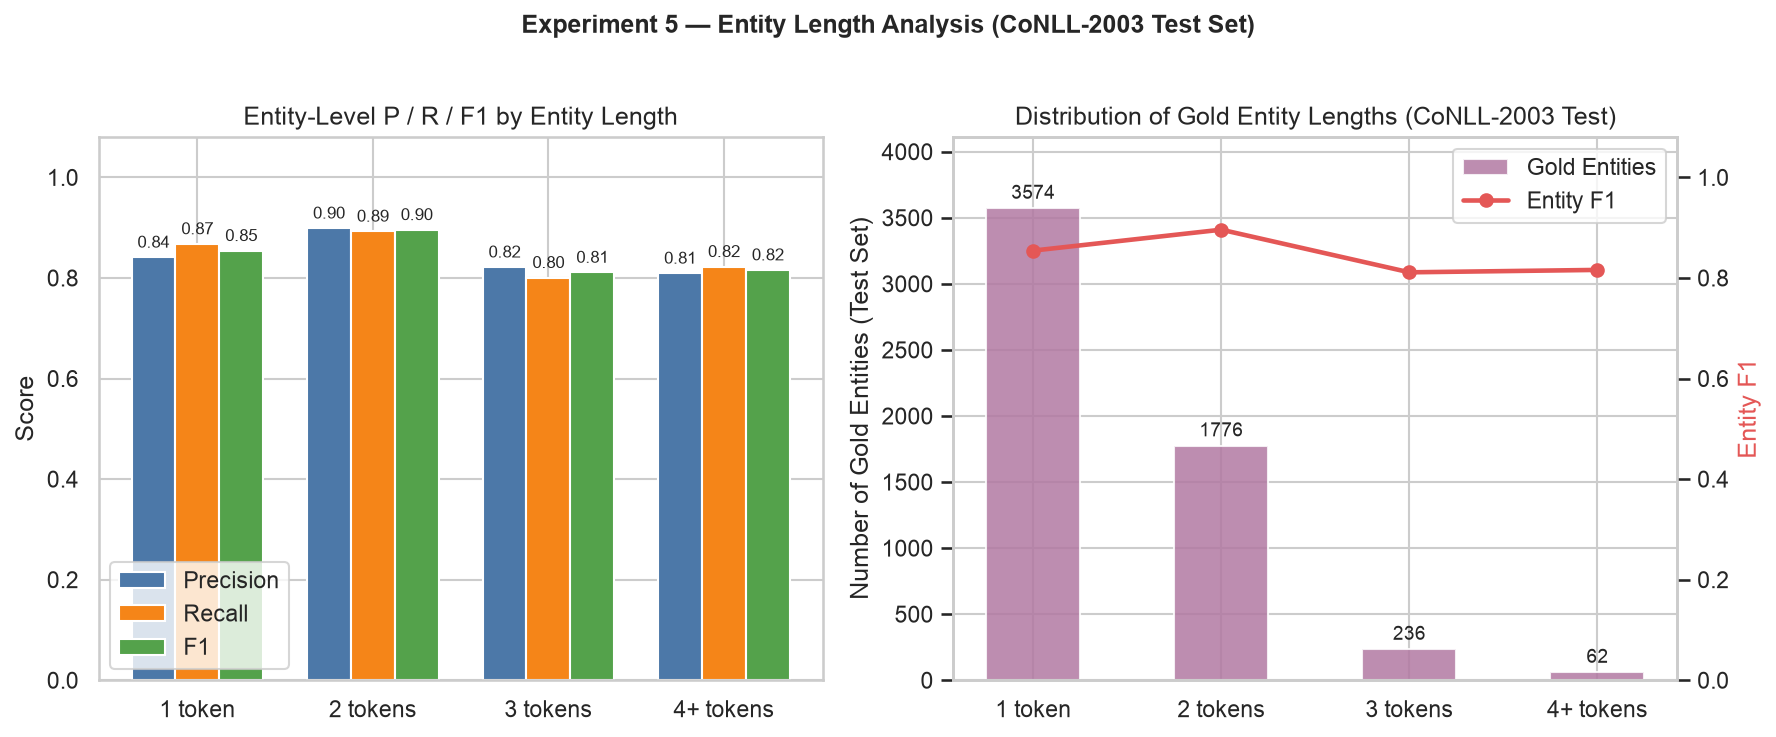

Saved /Users/user/NLP/LAB09/entity_length_analysis.png


In [8]:
def length_bucket(n_tokens: int) -> str:
    if n_tokens == 1:
        return "1"
    if n_tokens == 2:
        return "2"
    if n_tokens == 3:
        return "3"
    return "4+"

buckets = ["1", "2", "3", "4+"]
gold_counts = Counter()
pred_counts = Counter()
tp_counts = Counter()

for g_seq, p_seq in zip(test_golds, test_preds):
    g_ents = set(get_entities(g_seq))
    p_ents = set(get_entities(p_seq))
    for etype, s, e in g_ents:
        gold_counts[length_bucket(e - s + 1)] += 1
    for etype, s, e in p_ents:
        pred_counts[length_bucket(e - s + 1)] += 1
    for etype, s, e in (g_ents & p_ents):
        tp_counts[length_bucket(e - s + 1)] += 1

len_rows = []
for b in buckets:
    tp = tp_counts[b]
    gc = gold_counts[b]
    pc = pred_counts[b]
    p_b = tp / pc if pc > 0 else 0.0
    r_b = tp / gc if gc > 0 else 0.0
    f1_b = 2 * p_b * r_b / (p_b + r_b) if (p_b + r_b) > 0 else 0.0
    len_rows.append({
        "Entity length": b,
        "Gold_Count": gc,
        "Pred_Count": pc,
        "TP": tp,
        "Precision": round(p_b, 4),
        "Recall": round(r_b, 4),
        "F1": round(f1_b, 4),
    })

len_df = pd.DataFrame(len_rows)
print("=== Experiment 5: Entity-level Performance theo độ dài Entity ===")
display(len_df)

# Vẽ biểu đồ entity_length_analysis.png
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), dpi=150)

# Panel 1: Precision, Recall, F1 theo độ dài
x = np.arange(len(buckets))
width = 0.25
b1 = axes[0].bar(x - width, len_df["Precision"], width, label="Precision", color="#4C78A8")
b2 = axes[0].bar(x, len_df["Recall"], width, label="Recall", color="#F58518")
b3 = axes[0].bar(x + width, len_df["F1"], width, label="F1", color="#54A24B")

for bars in [b1, b2, b3]:
    for bar in bars:
        h = bar.get_height()
        axes[0].text(bar.get_x() + bar.get_width() / 2, h + 0.012, f"{h:.2f}", ha="center", va="bottom", fontsize=8)

axes[0].set_xticks(x)
axes[0].set_xticklabels(["1 token", "2 tokens", "3 tokens", "4+ tokens"])
axes[0].set_ylim(0, 1.08)
axes[0].set_ylabel("Score")
axes[0].set_title("Entity-Level P / R / F1 by Entity Length")
axes[0].legend(loc="lower left")

# Panel 2: Số lượng Gold Entity và Tỉ lệ F1
bar_g = axes[1].bar(x, len_df["Gold_Count"], width=0.5, color="#B279A2", alpha=0.85, label="Gold Entities")
for bar in bar_g:
    h = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width() / 2, h + 40, f"{int(h)}", ha="center", va="bottom", fontsize=9)
axes[1].set_xticks(x)
axes[1].set_xticklabels(["1 token", "2 tokens", "3 tokens", "4+ tokens"])
axes[1].set_ylabel("Number of Gold Entities (Test Set)")
axes[1].set_ylim(0, max(len_df["Gold_Count"]) * 1.15)
axes[1].set_title("Distribution of Gold Entity Lengths (CoNLL-2003 Test)")

ax2 = axes[1].twinx()
line_f1 = ax2.plot(x, len_df["F1"], color="#E45756", marker="o", linewidth=2.2, label="Entity F1")
ax2.set_ylim(0, 1.08)
ax2.set_ylabel("Entity F1", color="#E45756")
ax2.grid(False)
h1, l1 = axes[1].get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
axes[1].legend(h1 + h2, l1 + l2, loc="upper right")

fig.suptitle("Experiment 5 — Entity Length Analysis (CoNLL-2003 Test Set)", fontsize=12, fontweight="bold", y=1.02)
plt.tight_layout()
len_plot_path = LAB_DIR / "entity_length_analysis.png"
plt.savefig(len_plot_path, bbox_inches="tight", dpi=150)
plt.show()
print(f"Saved {len_plot_path}")

## 6. Ma trận nhầm lẫn & Trích xuất mẫu lỗi phục vụ Error Analysis

Vẽ ma trận nhầm lẫn trên toàn bộ 9 nhãn BIO của tập test (`confusion_matrix.png`) và lưu danh sách lỗi thực tế (False Positives, False Negatives, Boundary Errors, Context examples) ra scratch để đối chiếu khi viết `error_analysis.md`.

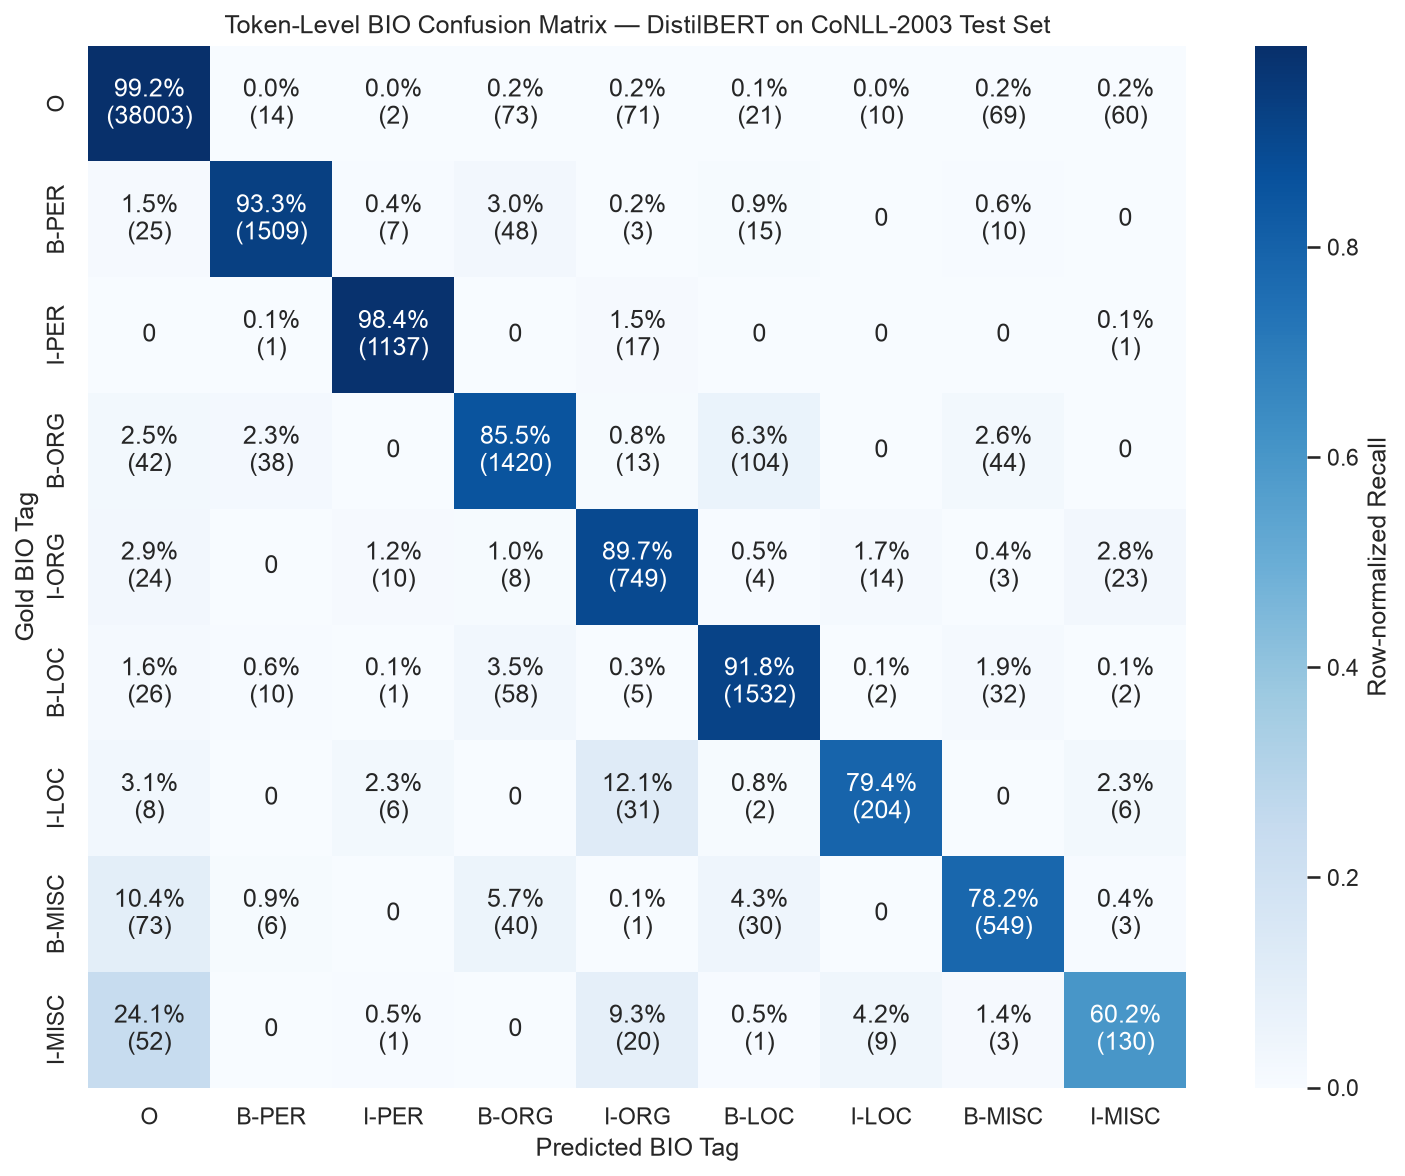

Saved /Users/user/NLP/LAB09/confusion_matrix.png


In [9]:
cm_raw = confusion_matrix(flat_gold, flat_pred, labels=LABEL_LIST)
cm_norm = cm_raw.astype(float) / np.maximum(cm_raw.sum(axis=1, keepdims=True), 1)

annot_labels = np.empty_like(cm_raw, dtype=object)
for i in range(len(LABEL_LIST)):
    for j in range(len(LABEL_LIST)):
        pct = cm_norm[i, j] * 100
        cnt = cm_raw[i, j]
        if cnt > 0:
            annot_labels[i, j] = f"{pct:.1f}%\n({cnt})"
        else:
            annot_labels[i, j] = "0"

plt.figure(figsize=(10, 8), dpi=150)
sns.heatmap(
    cm_norm,
    annot=annot_labels,
    fmt="",
    cmap="Blues",
    xticklabels=LABEL_LIST,
    yticklabels=LABEL_LIST,
    cbar_kws={"label": "Row-normalized Recall"},
)
plt.xlabel("Predicted BIO Tag")
plt.ylabel("Gold BIO Tag")
plt.title("Token-Level BIO Confusion Matrix — DistilBERT on CoNLL-2003 Test Set")
plt.tight_layout()
cm_path = LAB_DIR / "confusion_matrix.png"
plt.savefig(cm_path, bbox_inches="tight", dpi=150)
plt.show()
print(f"Saved {cm_path}")

In [10]:
# Trích xuất các lỗi thực tế và ví dụ Context Analysis (Mục 23 & 24) sang scratch
def span_text(words, s, e):
    return " ".join(words[s : e + 1])

def overlaps(a, b):
    return max(a[1], b[1]) <= min(a[2], b[2])

fp_examples = []
fn_examples = []
boundary_examples = []
type_mismatch_examples = []

# Đếm tần suất từ trong tập train để nhận diện rare entity
train_word_freq = Counter(w for row in train_raw for w in row["tokens"])

for s_idx, (words, g_seq, p_seq) in enumerate(zip(test_raw["tokens"], test_golds, test_preds)):
    g_ents = get_entities(g_seq)
    p_ents = get_entities(p_seq)
    g_set = set(g_ents)
    p_set = set(p_ents)

    sent_str = " ".join(words)
    if len(words) > 40:
        continue

    # False positives: predicted span không chồng lấn với bất kỳ gold span nào
    for pe in p_ents:
        if not any(overlaps(pe, ge) for ge in g_ents):
            txt = span_text(words, pe[1], pe[2])
            fp_examples.append({
                "test_idx": s_idx,
                "sentence": sent_str,
                "span_text": txt,
                "gold": "O",
                "prediction": f"{pe[0]} ({txt})",
                "train_freq": min(train_word_freq[w] for w in words[pe[1] : pe[2] + 1]),
            })

    # False negatives: gold span không chồng lấn với bất kỳ predicted span nào
    for ge in g_ents:
        if not any(overlaps(ge, pe) for pe in p_ents):
            txt = span_text(words, ge[1], ge[2])
            fn_examples.append({
                "test_idx": s_idx,
                "sentence": sent_str,
                "span_text": txt,
                "gold": f"{ge[0]} ({txt})",
                "prediction": "O",
                "train_freq": min(train_word_freq[w] for w in words[ge[1] : ge[2] + 1]),
            })

    # Boundary errors vs wrong entity type
    for ge in g_ents:
        if ge in p_set:
            continue
        for pe in p_ents:
            if overlaps(ge, pe):
                g_txt = span_text(words, ge[1], ge[2])
                p_txt = span_text(words, pe[1], pe[2])
                if (ge[1], ge[2]) != (pe[1], pe[2]):
                    boundary_examples.append({
                        "test_idx": s_idx,
                        "sentence": sent_str,
                        "gold": f"{ge[0]} ({g_txt})",
                        "prediction": f"{pe[0]} ({p_txt})",
                        "same_type": ge[0] == pe[0],
                    })
                elif ge[0] != pe[0]:
                    type_mismatch_examples.append({
                        "test_idx": s_idx,
                        "sentence": sent_str,
                        "span_text": g_txt,
                        "gold": f"{ge[0]} ({g_txt})",
                        "prediction": f"{pe[0]} ({p_txt})",
                    })

# Tìm surface forms xuất hiện trong test set với >= 2 loại gold entity khác nhau (Mục 24)
surface_occurrences = defaultdict(lambda: defaultdict(list))
for s_idx, (words, g_seq, p_seq) in enumerate(zip(test_raw["tokens"], test_golds, test_preds)):
    g_ents = get_entities(g_seq)
    for ge in g_ents:
        txt = span_text(words, ge[1], ge[2])
        p_slice = p_seq[ge[1] : ge[2] + 1]
        g_slice = g_seq[ge[1] : ge[2] + 1]
        surface_occurrences[txt][ge[0]].append({
            "test_idx": s_idx,
            "sentence": " ".join(words),
            "gold_type": ge[0],
            "gold_tags": g_slice,
            "pred_tags": p_slice,
            "exact_correct": p_slice == g_slice,
        })

context_candidates = {}
for surf, type_map in surface_occurrences.items():
    if len(type_map) >= 2 and surf.isalpha() and len(surf) >= 3:
        # Ưu tiên các ví dụ model đoán đúng ở cả các ngữ cảnh khác nhau
        cleaned = {}
        for k, occs in type_map.items():
            occs_sorted = sorted(occs, key=lambda d: (not d["exact_correct"], len(d["sentence"])))
            cleaned[k] = occs_sorted[:3]
        if sum(any(x["exact_correct"] for x in v) for v in cleaned.values()) >= 2:
            context_candidates[surf] = cleaned

dump_payload = {
    "results": results_df.to_dict(orient="records"),
    "entity_metrics": entity_df.to_dict(orient="records"),
    "length_metrics": len_df.to_dict(orient="records"),
    "history": history,
    "false_positives": fp_examples[:40],
    "false_negatives": fn_examples[:40],
    "boundary_errors": boundary_examples[:40],
    "type_mismatches": type_mismatch_examples[:30],
    "context_candidates": dict(list(context_candidates.items())[:25]),
}
ERROR_DUMP_PATH.write_text(json.dumps(dump_payload, indent=2, ensure_ascii=False), encoding="utf-8")
print(
    f"Saved error dump: FP={len(fp_examples)}, FN={len(fn_examples)}, "
    f"Boundary={len(boundary_examples)}, TypeMismatch={len(type_mismatch_examples)}, "
    f"ContextSurfaces={len(context_candidates)}"
)

Saved error dump: FP=187, FN=145, Boundary=267, TypeMismatch=332, ContextSurfaces=40
